# Damped Least-Squares Inverse Kinematics

Move a planar arm towards a reachable target using a regularised Jacobian inverse.

A two-link arm maps joint angles to a Cartesian endpoint. Near a straight-arm configuration its Jacobian is poorly conditioned. The damped least-squares correction solves a local approximation with a penalty on joint displacement. The damping improves numerical behaviour at the cost of slower convergence.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from control import forward_arm, jacobian_arm

## Check the differential model and reach the target

Finite differences independently verify the analytic Jacobian. Bound the step size and record the remaining Cartesian error after each update.

Initial error 0.7313 m | final 3.25e-06 m | updates 12


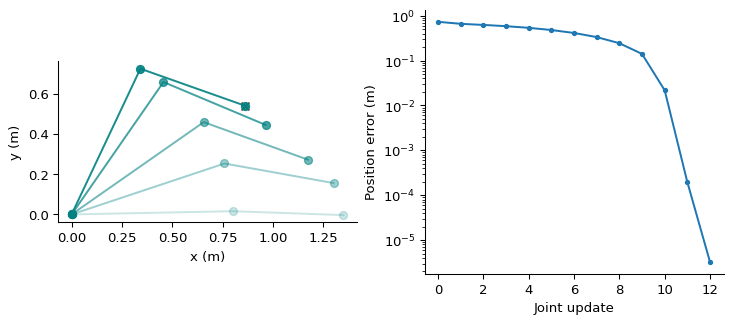

In [2]:
L = np.array([0.8, 0.55])
q = np.array([0.02, -0.055])
start = q.copy()
target = np.array([0.86, 0.54])
lam = 0.09
h = 1e-6
J = jacobian_arm(q, L)
num = np.column_stack(
    [(forward_arm(q + h * e, L)[-1] - forward_arm(q - h * e, L)[-1]) / (2 * h) for e in np.eye(2)]
)
assert np.allclose(J, num, atol=1e-8)
err = []
poses = [q.copy()]
for _ in range(65):
    e = target - forward_arm(q, L)[-1]
    err.append(np.linalg.norm(e))
    if err[-1] < 1e-5:
        break
    J = jacobian_arm(q, L)
    dq = J.T @ np.linalg.solve(J @ J.T + lam**2 * np.eye(2), e)
    q += dq * min(1, 0.18 / max(np.linalg.norm(dq), 1e-12))
    poses.append(q.copy())
print(f"Initial error {err[0]:.4f} m | final {err[-1]:.2e} m | updates {len(poses)-1}")
assert err[-1] < 1e-5
fig, (a, b) = plt.subplots(1, 2, figsize=(7.6, 3.3), constrained_layout=True)
for i in np.linspace(0, len(poses) - 1, 5, dtype=int):
    a.plot(
        *forward_arm(poses[i], L).T,
        "o-",
        alpha=0.2 + 0.7 * i / max(1, len(poses) - 1),
        color="teal",
    )
a.scatter(*target, marker="x", color="sienna")
a.set(aspect="equal", xlabel="x (m)", ylabel="y (m)")
b.semilogy(err, ".-")
b.set(xlabel="Joint update", ylabel="Position error (m)")
plt.show()

## Interpreting the result

The endpoint criterion measures task-space error. Different elbow configurations can reach the same target.

## Exercise

Move the target just outside the reachable workspace and record what the residual and joint updates do.

## References

[Wampler, damped least-squares inverse kinematics](https://doi.org/10.1109/TSMC.1986.289285)